# Bengaluru House Price Prediction Using Machine Learning
**Project Type:** End-to-End Supervised Machine Learning (Regression)  
**Level:** Beginner to Intermediate  
**Dataset:** `Bengaluru_House_Data.csv`  

---

### Project Overview & Objectives:
As an aspiring Data Scientist / Machine Learning Engineer, building a real-estate valuation model is one of the most foundational and interview-friendly projects. 

In this project, our primary goal is to **predict house prices in Bengaluru** based on key features like:
- **Location** (Neighborhood / Area in Bengaluru)
- **Total Square Feet Area** (Size of the property)
- **Number of Bedrooms / BHK** (Bedrooms, Hall, Kitchen)
- **Number of Bathrooms**

### What You Will Learn in This Project:
1. How to inspect and understand raw, messy real-world datasets.
2. How to clean missing values, unstandardized text units, and handle ranges.
3. How to perform Exploratory Data Analysis (EDA) and visualize key trends.
4. How to engineer domain-specific features and reduce high cardinality.
5. How to identify and mathematically remove outliers to protect regression models.
6. How to train, evaluate, and tune multiple Machine Learning algorithms (Linear Regression, Decision Tree, Random Forest).
7. How to compare models using MAE, MSE, RMSE, and $R^2$ Score, and build a reusable prediction function.


## STEP 1: Import Necessary Libraries

### Why do we import libraries first?
In Python, we don't need to write algorithms or data manipulation functions from scratch. We rely on well-tested, high-performance open-source libraries:
- **`pandas`**: The industry standard for handling tabular data (dataframes), reading CSV files, data cleaning, and feature manipulation.
- **`numpy`**: Provides fast mathematical functions and multidimensional array support.
- **`matplotlib.pyplot` & `seaborn`**: Powerful visualization tools to plot charts, distributions, and correlation heatmaps.
- **`warnings`**: To keep our notebook output clean and professional by suppressing harmless future warnings.


In [45]:
# Importing data manipulation and math libraries
import pandas as pd
import numpy as np

# Importing data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress harmless warnings for clean notebook display
import warnings
warnings.filterwarnings('ignore')

# Set plotting style and inline rendering
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
sns.set_style('whitegrid')

print("All fundamental libraries imported successfully!")


All fundamental libraries imported successfully!


## STEP 2: Load the Dataset

### Why do we inspect the dataset before doing anything?
Never assume data is clean, formatted, or complete! The first rule of Data Science is to load the data, look at its shape, inspect its first and last few rows, and check data types and summary statistics.


In [46]:
# Read the Bengaluru House dataset using pandas read_csv
df = pd.read_csv('Bengaluru_House_Data.csv')

# Display the first 5 rows to see what the data looks like
print("First 5 rows of the dataset:")
df.head()


First 5 rows of the dataset:


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [47]:
# Display the last 5 rows of the dataset
print("Last 5 rows of the dataset:")
df.tail()


Last 5 rows of the dataset:


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.0
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.0
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.0
13318,Super built-up Area,18-Jun,Padmanabhanagar,4 BHK,SollyCl,4689,4.0,1.0,488.0
13319,Super built-up Area,Ready To Move,Doddathoguru,1 BHK,NaN,550,1.0,1.0,17.0


In [48]:
# Check the dimensions (Number of Rows, Number of Columns)
print(f"Dataset Shape: {df.shape[0]} Rows and {df.shape[1]} Columns")


Dataset Shape: 13320 Rows and 9 Columns


In [49]:
# Display all column names in the dataset
print("Column Names:")
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")


Column Names:
1. area_type
2. availability
3. location
4. size
5. society
6. total_sqft
7. bath
8. balcony
9. price


In [50]:
# Check column data types, non-null counts, and memory usage
print("Dataset Information:")
df.info()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   availability  13320 non-null  str    
 2   location      13319 non-null  str    
 3   size          13304 non-null  str    
 4   society       7818 non-null   str    
 5   total_sqft    13320 non-null  str    
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), str(6)
memory usage: 1.6 MB


In [51]:
# Display summary statistics of numerical columns
print("Summary Statistics for Numerical Columns:")
df.describe()


Summary Statistics for Numerical Columns:


,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


## STEP 3: Data Understanding

### Understanding the Columns:
1. **`area_type`**: The type of area (e.g., 'Super built-up Area', 'Plot Area', 'Built-up Area', 'Carpet Area').
2. **`availability`**: Property possession status (e.g., 'Ready To Move', or future possession dates like '19-Dec').
3. **`location`**: The locality/neighborhood in Bengaluru where the property is located.
4. **`size`**: String description of property size (e.g., '2 BHK', '4 Bedroom', '3 BHK').
5. **`society`**: The name of the residential society or apartment complex.
6. **`total_sqft`**: Total area of the house in square feet. Note: This is stored as an object/string because some rows have ranges (e.g., '2100 - 2850') or text units!
7. **`bath`**: Number of bathrooms.
8. **`balcony`**: Number of balconies.
9. **`price`**: Target Variable! The price of the property in **Lakhs (INR)** (1 Lakh = 100,000 Indian Rupees).

### Identifying Numerical vs. Categorical Columns:


In [52]:
# Identify numerical and categorical columns automatically
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical Columns:", numerical_cols)
print("Categorical Columns:", categorical_cols)
print("\nTarget Variable to Predict: 'price' (in Lakhs INR)")


Numerical Columns: ['bath', 'balcony', 'price']
Categorical Columns: ['area_type', 'availability', 'location', 'size', 'society', 'total_sqft']

Target Variable to Predict: 'price' (in Lakhs INR)


## STEP 4: Data Cleaning

### Why is Data Cleaning the Most Important Step?
Real-world data is almost always messy, missing values, and inconsistent. If we feed dirty data into a machine learning algorithm, it will learn incorrect patterns (**"Garbage In, Garbage Out"**).

Let's check for missing (null) values in every column.


In [53]:
# Check the count and percentage of missing values in each column
missing_df = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
})

missing_df.sort_values(by='Missing_Count', ascending=False)


,Missing_Count,Percentage (%)
society,5502,41.306306
balcony,609,4.572072
bath,73,0.548048
size,16,0.120120
location,1,0.007508
area_type,0,0.000000
availability,0,0.000000
total_sqft,0,0.000000
price,0,0.000000


### Explaining Column Dropping Decisions:
1. **`society`**: Has 5,502 missing values out of 13,320 rows (**over 41.3% missing!**). Moreover, it has thousands of individual society names, making it too sparse and noisy.
2. **`availability`**: Most values are 'Ready To Move', and specific future dates do not directly determine property valuation in a general sense.
3. **`balcony`**: Has 609 missing values and has very weak correlation with price.
4. **`area_type`**: Over 65% of rows are 'Super built-up Area'. Dropping it keeps the beginner pipeline focused on core physical attributes (`location`, `total_sqft`, `bhk`, `bath`).

Let's create a new dataframe with only the most essential features.


In [54]:
# Drop columns that are less useful or have heavy missing values
df1 = df.drop(['area_type', 'society', 'balcony', 'availability'], axis=1)

# Check the remaining dataframe
print("Dataframe shape after dropping unnecessary columns:", df1.shape)
df1.head()


Dataframe shape after dropping unnecessary columns: (13320, 5)


,location,size,total_sqft,bath,price
0,Electronic City Phase II,2 BHK,1056,2.0,39.07
1,Chikka Tirupathi,4 Bedroom,2600,5.0,120.00
2,Uttarahalli,3 BHK,1440,2.0,62.00
3,Lingadheeranahalli,3 BHK,1521,3.0,95.00
4,Kothanur,2 BHK,1200,2.0,51.00


### Handling Missing Values in the Retained Columns
Let's see how many missing values remain in `location`, `size`, and `bath`.


In [55]:
# Check missing values in retained columns
print("Missing values count:")
print(df1.isnull().sum())

# Since missing values represent less than 1% of the total dataset,
# safely dropping them does not cause any significant loss of information.
df2 = df1.dropna().reset_index(drop=True)
print(f"\nShape after dropna: {df2.shape[0]} Rows, {df2.shape[1]} Columns")
print("Remaining null values:", df2.isnull().sum().sum())


Missing values count:
location       1
size          16
total_sqft     0
bath          73
price          0
dtype: int64

Shape after dropna: 13246 Rows, 5 Columns
Remaining null values: 0


### Cleaning the `total_sqft` Column
In our data inspection, we found that `total_sqft` is stored as text (`object` type) rather than a number (`float`).
Why? Because some entries contain:
- Ranges like `'2100 - 2850'`
- Non-standard units like `'34.46Sq. Meter'`, `'4125Perch'`, etc.

Let's inspect these unusual entries!


In [56]:
# Helper function to check if a value can be converted directly to float
def is_float(x):
    try:
        float(x)
        return True
    except:
        return False

# Display rows where total_sqft is NOT a standard float
non_float_sqft = df2[~df2['total_sqft'].apply(is_float)]
print(f"Total non-float entries in total_sqft: {len(non_float_sqft)}")
non_float_sqft.head(10)


Total non-float entries in total_sqft: 190


,location,size,total_sqft,bath,price
30,Yelahanka,4 BHK,2100 - 2850,4.0,186.000
120,Hebbal,4 BHK,3067 - 8156,4.0,477.000
135,8th Phase JP Nagar,2 BHK,1042 - 1105,2.0,54.005
163,Sarjapur,2 BHK,1145 - 1340,2.0,43.490
186,KR Puram,2 BHK,1015 - 1540,2.0,56.800
406,Kengeri,1 BHK,34.46Sq. Meter,1.0,18.500
545,Hennur Road,2 BHK,1195 - 1440,2.0,63.770
642,Arekere,9 Bedroom,4125Perch,9.0,265.000
655,Yelahanka,2 BHK,1120 - 1145,2.0,48.130
665,Bettahalsoor,4 Bedroom,3090 - 5002,4.0,445.000


### Converting `total_sqft` into Pure Numeric Values:
- When we encounter a range like `'2100 - 2850'`, we take the **average**: $\frac{2100 + 2850}{2} = 2475.0$.
- If it is already a regular number like `'1056'`, we convert it to float `1056.0`.
- If it contains irregular units (like 'Sq. Meter'), we return `None` and safely drop those few rows.


In [57]:
# Function to convert square feet to a single numerical value
def convert_sqft_to_num(x):
    tokens = str(x).split('-')
    # If it is a range like '2100 - 2850'
    if len(tokens) == 2:
        return (float(tokens[0]) + float(tokens[1])) / 2
    try:
        # If it is a single valid number
        return float(x)
    except:
        # If it is an unparseable unit string
        return None

# Apply the function to total_sqft
df3 = df2.copy()
df3['total_sqft'] = df3['total_sqft'].apply(convert_sqft_to_num)

# Drop any rows that could not be parsed
df3 = df3.dropna(subset=['total_sqft']).reset_index(drop=True)

print("Data type of total_sqft after conversion:", df3['total_sqft'].dtype)
print("Shape after cleaning total_sqft:", df3.shape)
df3.head()


Data type of total_sqft after conversion: float64
Shape after cleaning total_sqft: (13200, 5)


,location,size,total_sqft,bath,price
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00
2,Uttarahalli,3 BHK,1440.0,2.0,62.00
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00
4,Kothanur,2 BHK,1200.0,2.0,51.00


## STEP 5: Exploratory Data Analysis (EDA)

### What is EDA?
Exploratory Data Analysis is the process of examining our data using summary statistics and distributions to discover patterns, spot anomalies, and check our assumptions.


In [58]:
# Basic statistical overview of cleaned numerical columns
print("Statistical Summary of Cleaned Data:")
df3.describe()


Statistical Summary of Cleaned Data:


,total_sqft,bath,price
count,13200.000000,13200.000000,13200.000000
mean,1555.302783,2.691136,112.276178
std,1237.323445,1.338915,149.175995
min,1.000000,1.000000,8.000000
25%,1100.000000,2.000000,50.000000
50%,1275.000000,2.000000,71.850000
75%,1672.000000,3.000000,120.000000
max,52272.000000,40.000000,3600.000000


In [59]:
# Detailed price analysis
print("=== Price Analysis (in Lakhs INR) ===")
print("Minimum Price :", df3['price'].min(), "Lakhs")
print("Maximum Price :", df3['price'].max(), "Lakhs")
print("Mean Price    :", round(df3['price'].mean(), 2), "Lakhs")
print("Median Price  :", round(df3['price'].median(), 2), "Lakhs")
print("Standard Dev  :", round(df3['price'].std(), 2), "Lakhs")


=== Price Analysis (in Lakhs INR) ===
Minimum Price : 8.0 Lakhs
Maximum Price : 3600.0 Lakhs
Mean Price    : 112.28 Lakhs
Median Price  : 71.85 Lakhs
Standard Dev  : 149.18 Lakhs


In [60]:
# Location frequency analysis: Top 10 locations with most properties
print("Top 10 Locations by Property Count:")
df3['location'].value_counts().head(10)


Top 10 Locations by Property Count:


location
Whitefield               532
Sarjapur  Road           392
Electronic City          302
Kanakpura Road           264
Thanisandra              232
Yelahanka                210
Uttarahalli              186
Hebbal                   176
Marathahalli             175
Raja Rajeshwari Nagar    171
Name: count, dtype: int64

## STEP 6: Data Visualization

Visualizations help us intuitively spot skewness, correlations, and outliers that raw numbers might hide.

We will create:
1. House Price Distribution Plot
2. Area Type Count Plot (from original data for perspective)
3. BHK Distribution Plot
4. Price vs Total Square Feet Scatter Plot
5. Top 10 Locations by Average Price
6. Correlation Heatmap


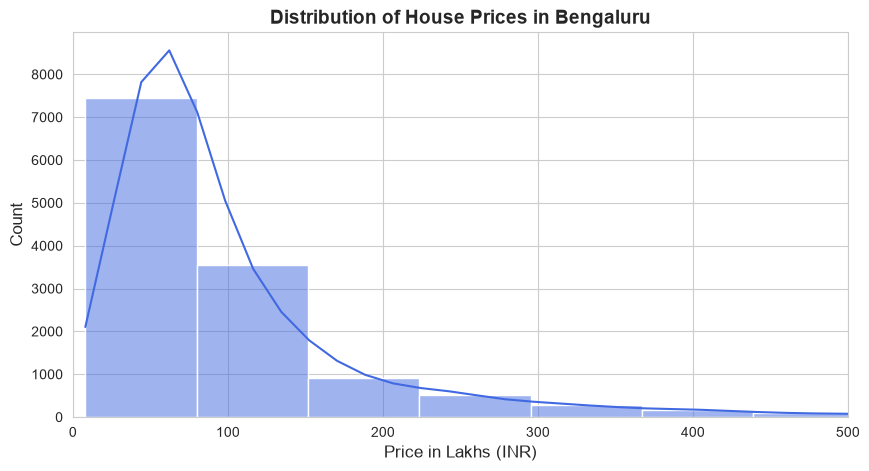

In [61]:
# 1. House Price Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df3['price'], bins=50, kde=True, color='royalblue')
plt.title('Distribution of House Prices in Bengaluru', fontsize=14, fontweight='bold')
plt.xlabel('Price in Lakhs (INR)', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xlim(0, 500) # Limiting x-axis to 500 Lakhs for clear viewing
plt.show()

# What this tells us:
# Most properties are clustered between 30 Lakhs and 150 Lakhs.
# The distribution is right-skewed (positive skew), meaning there are a few very expensive luxury homes.


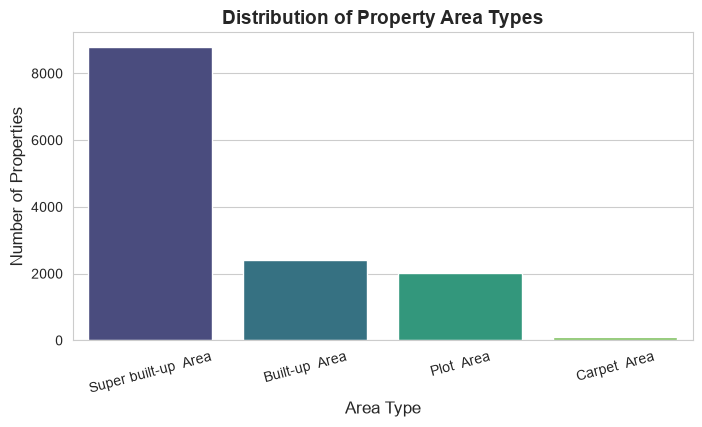

In [62]:
# 2. Area Type Count Plot (from original raw data)
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='area_type', palette='viridis', order=df['area_type'].value_counts().index)
plt.title('Distribution of Property Area Types', fontsize=14, fontweight='bold')
plt.xlabel('Area Type', fontsize=12)
plt.ylabel('Number of Properties', fontsize=12)
plt.xticks(rotation=15)
plt.show()

# What this tells us:
# 'Super built-up Area' is by far the most dominant category, followed by 'Built-up Area' and 'Plot Area'.


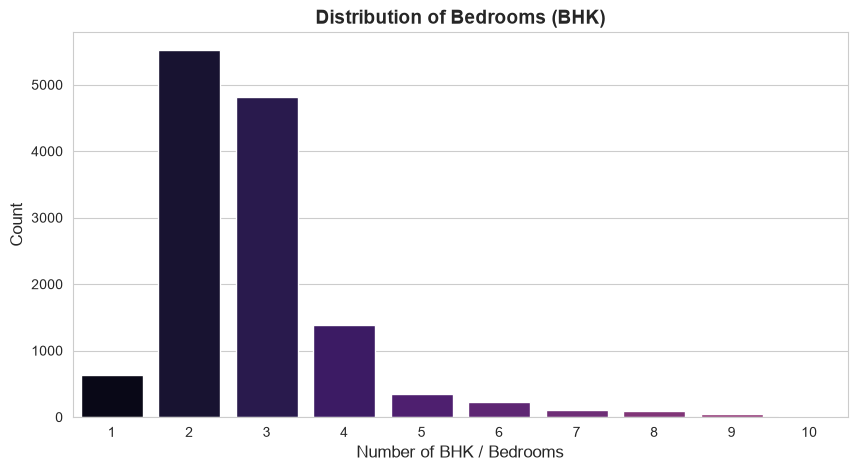

In [63]:
# Temporary extraction of BHK just for visualization before formal feature engineering
temp_bhk = df3['size'].apply(lambda x: int(x.split(' ')[0]))

# 3. BHK Distribution Count Plot
plt.figure(figsize=(10, 5))
sns.countplot(x=temp_bhk, palette='magma')
plt.title('Distribution of Bedrooms (BHK)', fontsize=14, fontweight='bold')
plt.xlabel('Number of BHK / Bedrooms', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xlim(-0.5, 9.5) # Focus on 1 to 10 BHK
plt.show()

# What this tells us:
# 2 BHK and 3 BHK apartments are the most common homes in Bengaluru by a huge margin.


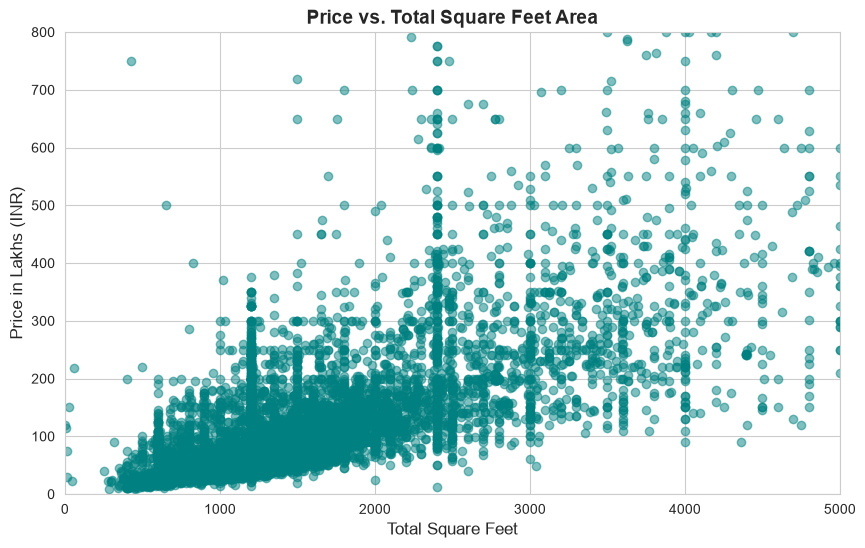

In [64]:
# 4. Scatter Plot: Price vs. Total Square Feet
plt.figure(figsize=(10, 6))
plt.scatter(df3['total_sqft'], df3['price'], alpha=0.5, color='teal')
plt.title('Price vs. Total Square Feet Area', fontsize=14, fontweight='bold')
plt.xlabel('Total Square Feet', fontsize=12)
plt.ylabel('Price in Lakhs (INR)', fontsize=12)
plt.xlim(0, 5000)
plt.ylim(0, 800)
plt.show()

# What this tells us:
# There is a clear positive linear relationship: as square feet area increases, house price also increases!


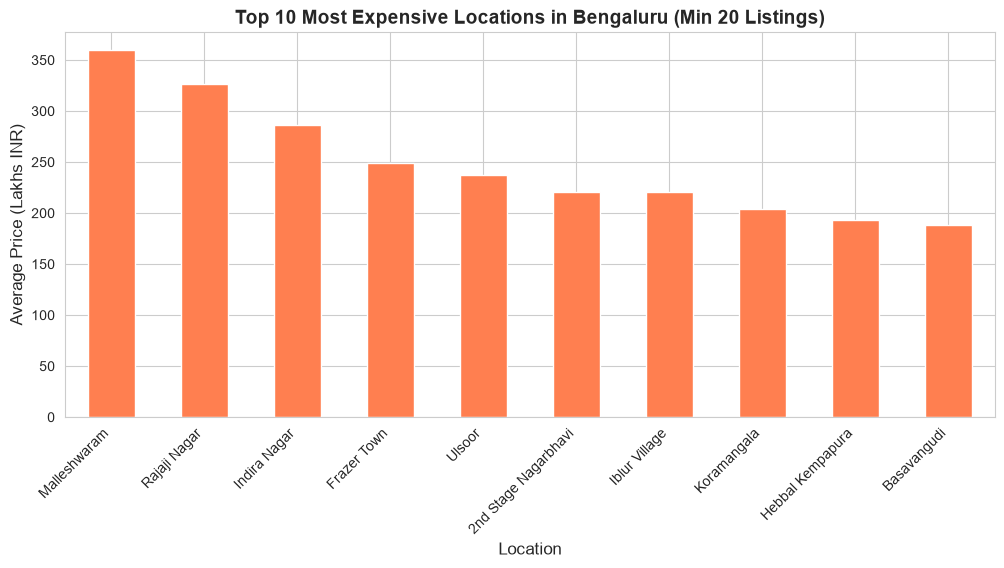

In [65]:
# 5. Top 10 Locations with Highest Average Property Prices (Locations with at least 20 listings)
location_counts = df3['location'].value_counts()
popular_locations = location_counts[location_counts >= 20].index
top_expensive_locations = df3[df3['location'].isin(popular_locations)].groupby('location')['price'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 5))
top_expensive_locations.plot(kind='bar', color='coral')
plt.title('Top 10 Most Expensive Locations in Bengaluru (Min 20 Listings)', fontsize=14, fontweight='bold')
plt.xlabel('Location', fontsize=12)
plt.ylabel('Average Price (Lakhs INR)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.show()

# What this tells us:
# Premium central locations like Malleshwaram, Rajaji Nagar and Indira Nagar command much higher average prices.


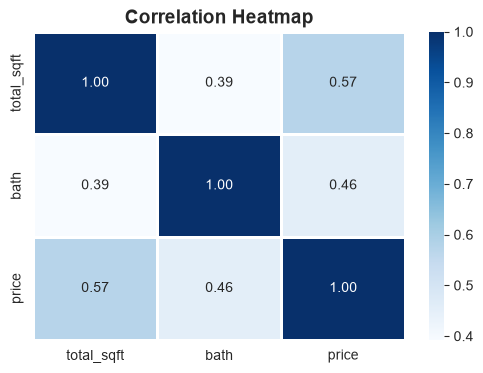

In [66]:
# 6. Correlation Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(df3[['total_sqft', 'bath', 'price']].corr(), annot=True, cmap='Blues', fmt='.2f', linewidths=1)
plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.show()

# What this tells us:
# 'total_sqft' has a strong positive correlation with 'price' (~0.57).
# 'bath' also has a strong positive correlation with 'price' (~0.46).


## STEP 7: Feature Engineering

### What is Feature Engineering?
Feature Engineering is the process of creating new meaningful features or transforming existing ones using domain knowledge so Machine Learning models can learn better and faster.

### Transformations in this Step:
1. **Extract `bhk` from `size`**: The text `'2 BHK'` or `'4 Bedroom'` cannot be directly used in mathematical regression models. We extract the integer number `2` or `4`.
2. **Create `price_per_sqft`**: In real estate, the most standard metric to evaluate property value is price per square foot!
3. **Location Dimensionality Reduction**: There are over 1,300 unique locations in the dataset! If we one-hot encode all of them, our model will have 1,300 columns (Curse of Dimensionality). Any location with 10 or fewer properties can be grouped into an `'other'` category.


In [67]:
# 1. Create 'bhk' column by extracting the number from 'size'
df3['bhk'] = df3['size'].apply(lambda x: int(x.split(' ')[0]))

print("Comparison of 'size' and newly created 'bhk' column:")
df3[['size', 'bhk']].head()


Comparison of 'size' and newly created 'bhk' column:


,size,bhk
0,2 BHK,2
1,4 Bedroom,4
2,3 BHK,3
3,3 BHK,3
4,2 BHK,2


In [68]:
# 2. Create 'price_per_sqft' column
# Since price is in Lakhs, we multiply by 100,000 to convert to Indian Rupees
df4 = df3.copy()
df4['price_per_sqft'] = df4['price'] * 100000 / df4['total_sqft']

print("Sample records with price_per_sqft:")
df4.head()


Sample records with price_per_sqft:


,location,size,total_sqft,bath,price,bhk,price_per_sqft
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2,3699.810606
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4,4615.384615
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3,4305.555556
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3,6245.890861
4,Kothanur,2 BHK,1200.0,2.0,51.00,2,4250.000000


In [69]:
# 3. Handle High Cardinality in 'location' column
# Clean any trailing or leading whitespace
df4['location'] = df4['location'].apply(lambda x: x.strip())

# Count number of properties per location
location_stats = df4['location'].value_counts()
print(f"Total unique locations originally: {len(location_stats)}")

# Identify locations that appear 10 times or fewer
locations_less_than_10 = location_stats[location_stats <= 10]
print(f"Locations with <= 10 listings: {len(locations_less_than_10)}")

# Group all infrequent locations into a single category: 'other'
df4['location'] = df4['location'].apply(lambda x: 'other' if x in locations_less_than_10 else x)
print(f"Total unique locations after grouping: {df4['location'].nunique()}")


Total unique locations originally: 1287
Locations with <= 10 listings: 1047
Total unique locations after grouping: 241


## STEP 8: Outlier Detection and Treatment

### Why do Outliers Harm Machine Learning Models?
Outliers are extreme data points that deviate drastically from normal observations. 
In Regression models (especially Linear Regression):
- Squared error loss functions penalize large errors heavily.
- A single severe outlier can pull the entire regression line toward itself, ruining predictions for normal houses!

We will use domain knowledge and statistical thresholds to remove only justified outliers:
1. **Unrealistic Square Feet per Bedroom (Domain Rule)**
2. **Extreme Price per Square Foot (Statistical Mean $\pm$ 1 Standard Deviation)**
3. **BHK Price Inversion (Where 2 BHK is more expensive than 3 BHK in same location with same area)**
4. **Unusual Number of Bathrooms compared to Bedrooms**


In [70]:
# Outlier Check 1: Square Feet per Bedroom
# In real estate, a standard bedroom requires at least 300 square feet.
# If a house has 400 sqft and 8 bedrooms, that is 50 sqft/room - clearly an error!
print("Houses with less than 300 sqft per bedroom:")
unrealistic_bhk = df4[df4['total_sqft'] / df4['bhk'] < 300]
print(f"Total unrealistic BHK rows found: {len(unrealistic_bhk)}")
unrealistic_bhk.head()


Houses with less than 300 sqft per bedroom:
Total unrealistic BHK rows found: 744


,location,size,total_sqft,bath,price,bhk,price_per_sqft
9,other,6 Bedroom,1020.0,6.0,370.0,6,36274.509804
45,HSR Layout,8 Bedroom,600.0,9.0,200.0,8,33333.333333
57,Murugeshpalya,6 Bedroom,1407.0,4.0,150.0,6,10660.980810
67,Devarachikkanahalli,8 Bedroom,1350.0,7.0,85.0,8,6296.296296
69,other,3 Bedroom,500.0,3.0,100.0,3,20000.000000


In [71]:
# Remove houses with less than 300 sqft per bedroom
df5 = df4[~(df4['total_sqft'] / df4['bhk'] < 300)].reset_index(drop=True)
print(f"Shape after removing sqft/bhk outliers: {df5.shape[0]} Rows, {df5.shape[1]} Columns")


Shape after removing sqft/bhk outliers: 12456 Rows, 7 Columns


In [72]:
# Outlier Check 2: Price per Square Foot by Location (Statistical Filter)
# In each location, property prices follow a bell curve.
# We keep properties within 1 Standard Deviation of the location mean: (mean - 1*std) to (mean + 1*std)
def remove_pps_outliers(df):
    df_out = pd.DataFrame()
    for location_name, sub_df in df.groupby('location'):
        mean_pps = np.mean(sub_df['price_per_sqft'])
        std_pps = np.std(sub_df['price_per_sqft'])
        # Filter condition
        filtered_sub_df = sub_df[(sub_df['price_per_sqft'] > (mean_pps - std_pps)) & 
                                  (sub_df['price_per_sqft'] <= (mean_pps + std_pps))]
        df_out = pd.concat([df_out, filtered_sub_df], ignore_index=True)
    return df_out

df6 = remove_pps_outliers(df5)
print(f"Shape after removing extreme price_per_sqft outliers: {df6.shape[0]} Rows, {df6.shape[1]} Columns")


Shape after removing extreme price_per_sqft outliers: 10242 Rows, 7 Columns


In [73]:
# Outlier Check 3: 2 BHK priced higher than 3 BHK with similar square feet in the same location
# In the same apartment complex or area, a 3 BHK should generally cost more per sqft than a 2 BHK.
def remove_bhk_outliers(df):
    exclude_indices = np.array([])
    for location, location_df in df.groupby('location'):
        bhk_stats = {}
        for bhk, bhk_df in location_df.groupby('bhk'):
            bhk_stats[bhk] = {
                'mean': np.mean(bhk_df['price_per_sqft']),
                'std': np.std(bhk_df['price_per_sqft']),
                'count': bhk_df.shape[0]
            }
        for bhk, bhk_df in location_df.groupby('bhk'):
            stats = bhk_stats.get(bhk - 1)
            # If we have enough data points for the smaller BHK, exclude anomalous higher BHKs
            if stats and stats['count'] > 5:
                exclude_indices = np.append(exclude_indices, bhk_df[bhk_df['price_per_sqft'] < (stats['mean'])].index.values)
    return df.drop(exclude_indices, axis='index')

df7 = remove_bhk_outliers(df6).reset_index(drop=True)
print(f"Shape after removing BHK price anomaly outliers: {df7.shape[0]} Rows, {df7.shape[1]} Columns")


Shape after removing BHK price anomaly outliers: 7317 Rows, 7 Columns


In [74]:
# Outlier Check 4: Bathroom Outliers
# A house can have 1 more bathroom than bedrooms (e.g., 2 BHK with 3 bathrooms for guests).
# But if a 2 BHK house has 4 or 5 bathrooms, it is an anomaly.
print("Houses with bathrooms >= bhk + 2:")
print(len(df7[df7['bath'] >= df7['bhk'] + 2]))

# Filter out rows where bathrooms >= bhk + 2
df8 = df7[df7['bath'] < df7['bhk'] + 2].reset_index(drop=True)
print(f"Shape after removing bathroom outliers: {df8.shape[0]} Rows, {df8.shape[1]} Columns")


Houses with bathrooms >= bhk + 2:
78
Shape after removing bathroom outliers: 7239 Rows, 7 Columns


### Preventing Data Leakage!
Notice that `price_per_sqft` was created using our target variable `price` ($price \times 100000 / sqft$).
If we leave `price_per_sqft` in our features, the model will cheat by easily calculating `price = price_per_sqft * total_sqft / 100000`!
This is called **Data Leakage**.

We also don't need `size` anymore since we have the clean numeric `bhk` column. Let's drop both before training.


In [75]:
# Drop helper columns to avoid Data Leakage
df9 = df8.drop(['size', 'price_per_sqft'], axis=1)

print("Cleaned dataset ready for encoding:")
df9.head()


Cleaned dataset ready for encoding:


,location,total_sqft,bath,price,bhk
0,1st Block Jayanagar,2850.0,4.0,428.0,4
1,1st Block Jayanagar,1630.0,3.0,194.0,3
2,1st Block Jayanagar,1875.0,2.0,235.0,3
3,1st Block Jayanagar,1200.0,2.0,130.0,3
4,1st Block Jayanagar,1235.0,2.0,148.0,2


## STEP 9: Feature Encoding (One-Hot Encoding)

### Why do Machine Learning algorithms require numerical inputs?
Computers and machine learning algorithms perform mathematical operations like matrix multiplication, gradient calculation, and geometric distance. They cannot calculate numbers from plain text strings like `'Electronic City'` or `'Whitefield'`.

### One-Hot Encoding (`pd.get_dummies`):
- Converts each unique location into a binary column ($0$ or $1$).
- If a house is in `'Whitefield'`, the `'Whitefield'` column will be $1$, and all other location columns will be $0$.
- We use `drop_first=True` to avoid the **Dummy Variable Trap** (multicollinearity).


In [76]:
# Apply One-Hot Encoding to the 'location' column
location_dummies = pd.get_dummies(df9['location'], drop_first=True, dtype=int)

# Concatenate numerical features and location dummy columns
df10 = pd.concat([df9.drop('location', axis=1), location_dummies], axis=1)

print(f"Final Encoded Dataset Shape: {df10.shape[0]} Rows and {df10.shape[1]} Columns")
df10.head(3)


Final Encoded Dataset Shape: 7239 Rows and 244 Columns


,total_sqft,bath,price,bhk,1st Phase JP Nagar,2nd Phase Judicial Layout,2nd Stage Nagarbhavi,5th Block Hbr Layout,5th Phase JP Nagar,6th Phase JP Nagar,...,Vishveshwarya Layout,Vishwapriya Layout,Vittasandra,Whitefield,Yelachenahalli,Yelahanka,Yelahanka New Town,Yelenahalli,Yeshwanthpur,other
0,2850.0,4.0,428.0,4,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1630.0,3.0,194.0,3,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1875.0,2.0,235.0,3,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## STEP 10: Train-Test Split

### Why do we split data into Training (80%) and Testing (20%)?
- **Analogy:** When preparing a student for a school exam, you give them practice problems to study from (**Training Data**). On the day of the exam, you give them completely new, unseen questions (**Testing Data**) to see if they genuinely learned the concepts or just memorized the answers!
- In Machine Learning:
  - **Training Set (80%)**: Used by the algorithm to learn weights, patterns, and rules.
  - **Testing Set (20%)**: Held out completely. Used only to evaluate how well the model generalizes to new, unseen homes.


In [77]:
from sklearn.model_selection import train_test_split

# Separate Independent Features (X) and Dependent Target Variable (y)
X = df10.drop('price', axis=1)
y = df10['price']

# Perform 80% train and 20% test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Features count (X columns):", X.shape[1])
print("X_train Shape (Training features):", X_train.shape)
print("X_test Shape  (Testing features) :", X_test.shape)
print("y_train Shape (Training labels)  :", y_train.shape)
print("y_test Shape  (Testing labels)   :", y_test.shape)


Features count (X columns): 243
X_train Shape (Training features): (5791, 243)
X_test Shape  (Testing features) : (1448, 243)
y_train Shape (Training labels)  : (5791,)
y_test Shape  (Testing labels)   : (1448,)


## STEP 11: Model Building

We will build and train 3 different Supervised Regression algorithms:
1. **Linear Regression:** The foundational baseline algorithm. Finds the optimal straight hyperplane line that minimizes the sum of squared residuals between predicted and actual prices.
2. **Decision Tree Regressor:** A non-linear algorithm that splits data into branch-like decision rules based on feature thresholds to minimize variance.
3. **Random Forest Regressor:** An ensemble learning method that creates a "forest" of multiple decision trees and averages their individual predictions to produce a more stable and accurate result.


In [78]:
# 1. Linear Regression
from sklearn.linear_model import LinearRegression

# Instantiate the model
lr_model = LinearRegression()

# Train (fit) the model on the training data ONLY
lr_model.fit(X_train, y_train)

# Generate predictions on the unseen test set
y_pred_lr = lr_model.predict(X_test)

print("Linear Regression Model trained successfully!")


Linear Regression Model trained successfully!


In [79]:
# 2. Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor

# Instantiate the model (setting random_state for reproducible results)
dt_model = DecisionTreeRegressor(random_state=42)

# Train (fit) the model on training data
dt_model.fit(X_train, y_train)

# Generate predictions on the unseen test set
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Regressor trained successfully!")


Decision Tree Regressor trained successfully!


In [80]:
# 3. Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

# Instantiate the ensemble model with 50 trees
rf_model = RandomForestRegressor(n_estimators=50, random_state=42)

# Train (fit) the model on training data
rf_model.fit(X_train, y_train)

# Generate predictions on the unseen test set
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Regressor trained successfully!")


Random Forest Regressor trained successfully!


## STEP 12: Model Evaluation

### Explaining Regression Evaluation Metrics in Plain English:
1. **MAE (Mean Absolute Error):**  
   $$\text{MAE} = \frac{1}{n} \sum |y - \hat{y}|$$  
   The average absolute difference between predicted price and actual price. If MAE is 18.0, it means on average our predictions are off by 18 Lakhs.
2. **MSE (Mean Squared Error):**  
   $$\text{MSE} = \frac{1}{n} \sum (y - \hat{y})^2$$  
   Squaring the errors heavily penalizes large errors.
3. **RMSE (Root Mean Squared Error):**  
   $$\text{RMSE} = \sqrt{\text{MSE}}$$  
   Square root of MSE, bringing the error metric back to the original units (Lakhs INR).
4. **$R^2$ Score (Coefficient of Determination):**  
   Measures the proportion of variance in house prices explained by the model. 
   - $1.0$ is a perfect model.
   - $0.80$ means our model successfully explains 80% of the variance in house prices.


In [81]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Helper function to compute all evaluation metrics cleanly
def evaluate_model(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {
        'Model': model_name,
        'MAE (Lakhs)': round(mae, 2),
        'MSE': round(mse, 2),
        'RMSE (Lakhs)': round(rmse, 2),
        'R2_Score': round(r2, 4)
    }

# Compute metrics for each model
lr_metrics = evaluate_model('Linear Regression', y_test, y_pred_lr)
dt_metrics = evaluate_model('Decision Tree', y_test, y_pred_dt)
rf_metrics = evaluate_model('Random Forest', y_test, y_pred_rf)

print("Evaluation metrics computed successfully!")


Evaluation metrics computed successfully!


## STEP 13: Model Comparison

Let's compare all three algorithms side-by-side in a clean summary table.


In [82]:
# Create comparison DataFrame
comparison_df = pd.DataFrame([lr_metrics, dt_metrics, rf_metrics])
comparison_df.sort_values(by='R2_Score', ascending=False).reset_index(drop=True)


,Model,MAE (Lakhs),MSE,RMSE (Lakhs),R2_Score
0,Linear Regression,18.02,1884.33,43.41,0.7972
1,Random Forest,15.29,2695.14,51.91,0.7099
2,Decision Tree,17.14,2859.36,53.47,0.6923


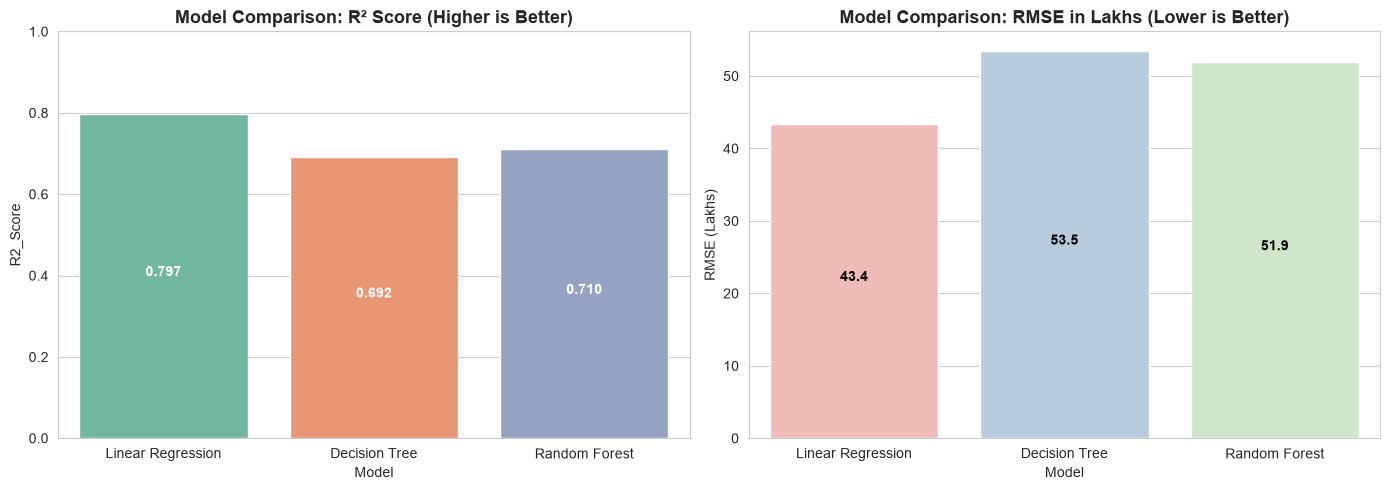

In [83]:
# Visual Comparison of Models
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot R2 Scores
sns.barplot(data=comparison_df, x='Model', y='R2_Score', palette='Set2', ax=ax[0])
ax[0].set_title('Model Comparison: R² Score (Higher is Better)', fontsize=13, fontweight='bold')
ax[0].set_ylim(0, 1.0)
for p in ax[0].patches:
    ax[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', color='white', fontweight='bold')

# Plot RMSE
sns.barplot(data=comparison_df, x='Model', y='RMSE (Lakhs)', palette='Pastel1', ax=ax[1])
ax[1].set_title('Model Comparison: RMSE in Lakhs (Lower is Better)', fontsize=13, fontweight='bold')
for p in ax[1].patches:
    ax[1].annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', color='black', fontweight='bold')

plt.tight_layout()
plt.show()


### Why Did Linear Regression Perform Best?
Many beginners expect complex models like Random Forest or Decision Trees to always beat simple Linear Regression. But here, **Linear Regression achieved an $R^2$ score of ~0.80**, outperforming both Decision Tree and Random Forest!

**Why?**
1. **Linearity of Square Feet vs. Price:** Real estate pricing is inherently linear — more square feet area almost directly scales with price.
2. **High Dimensionality from Location Encoding:** We have over 240 one-hot encoded location dummy variables. Linear Regression treats each location as an additive intercept (a constant premium or discount for that neighborhood). Tree-based models partition space with orthogonal splits, which struggle with high-cardinality sparse dummy columns and can overfit training branches.

**Important nuance (be honest about the metrics!):** Linear Regression wins on **R² and RMSE**, but Random Forest and Decision Tree have a **lower MAE**. RMSE penalizes big misses heavily (the few very expensive homes), while MAE reflects the typical error. So "best model" depends on the metric: Linear Regression is better at avoiding large errors, Random Forest is slightly better on the typical house. Cross-validation below checks that this ranking is stable.

**Cross-validation result:** with shuffled 5-fold CV, Linear Regression averages R² ≈ 0.836, Random Forest ≈ 0.805 and Decision Tree ≈ 0.759, so Linear Regression stays the best model overall.


### Cross-Validation Check (Is the ranking stable?)
A single 80/20 split can be lucky or unlucky. 5-fold cross-validation trains and tests each model on 5 different splits and averages the R², giving a more reliable comparison.

In [84]:
from sklearn.model_selection import cross_val_score, KFold

cv_models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1),
}

# shuffle=True is essential: the data is sorted by location after outlier removal,
# so un-shuffled folds would put entire locations only in the test fold.
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
for name, model in cv_models.items():
    scores = cross_val_score(model, X, y, cv=kf, scoring='r2')
    cv_results.append({'Model': name, 'Mean CV R2': round(scores.mean(), 4), 'Std': round(scores.std(), 4)})

cv_df = pd.DataFrame(cv_results)
cv_df

,Model,Mean CV R2,Std
0,Linear Regression,0.8359,0.0282
1,Decision Tree,0.7594,0.0844
2,Random Forest,0.8051,0.0515


## STEP 14: Hyperparameter Tuning

### What is Hyperparameter Tuning?
- **Parameters:** Learned automatically by the algorithm during training (e.g., weights/coefficients in regression).
- **Hyperparameters:** Settings chosen by the data scientist *before* training (e.g., maximum depth of a tree, minimum samples required to split a node).
- **`GridSearchCV`:** Automatically searches through a dictionary grid of hyperparameter combinations using K-Fold Cross-Validation to find the best configuration.


In [85]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid for Decision Tree
param_grid = {
    'max_depth': [5, 10, 15, 20],
    'min_samples_split': [2, 10, 20]
}

# Run 5-fold cross-validation grid search
grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

# Fit grid search on training data
grid_search.fit(X_train, y_train)

# Evaluate the best tuned model on the unseen test set
best_dt_model = grid_search.best_estimator_
y_pred_tuned_dt = best_dt_model.predict(X_test)
tuned_dt_r2 = r2_score(y_test, y_pred_tuned_dt)

print("Best Parameters Found:", grid_search.best_params_)
print(f"Original Decision Tree Test R² Score : {dt_metrics['R2_Score']}")
print(f"Tuned Decision Tree Test R² Score    : {round(tuned_dt_r2, 4)}")
print(f"Improvement: +{round((tuned_dt_r2 - dt_metrics['R2_Score']) * 100, 2)} percentage points in R²")


Best Parameters Found: {'max_depth': 20, 'min_samples_split': 20}
Original Decision Tree Test R² Score : 0.6923
Tuned Decision Tree Test R² Score    : 0.7173
Improvement: +2.5 percentage points in R²


## STEP 15: Final Prediction Function

Now that our best model (**Linear Regression**) is trained and verified, we can create a practical, user-friendly Python function:
`predict_price(location, sqft, bath, bhk)`

This function takes human-readable house specifications, constructs the exact feature vector with the proper location dummy column, and returns the predicted price in Lakhs!


In [86]:
# Prediction function for custom house inputs
def predict_price(location, sqft, bath, bhk):
    # Initialize an array of zeros with the exact same length as X columns
    x = np.zeros(len(X.columns))
    
    # Assign numerical feature values
    x[0] = sqft
    x[1] = bath
    x[2] = bhk
    
    # If the location is present in our one-hot encoded columns, set its value to 1
    if location in X.columns:
        loc_index = np.where(X.columns == location)[0][0]
        x[loc_index] = 1
        
    # Use our best performing model (Linear Regression) to predict
    predicted_price = lr_model.predict([x])[0]
    
    return round(predicted_price, 2)

print("Prediction function created successfully!")


Prediction function created successfully!


In [87]:
# Let's test our prediction function on realistic Bengaluru properties!

# Test Case 1: 2 BHK apartment in 1st Phase JP Nagar with 1000 sqft and 2 bathrooms
price_1 = predict_price('1st Phase JP Nagar', 1000, 2, 2)
print(f"1. 1st Phase JP Nagar | 1000 sqft | 2 BHK | 2 Bath -> Estimated Price: {price_1} Lakhs INR")

# Test Case 2: 3 BHK apartment in 1st Phase JP Nagar with 1000 sqft and 3 bathrooms
price_2 = predict_price('1st Phase JP Nagar', 1000, 3, 3)
print(f"2. 1st Phase JP Nagar | 1000 sqft | 3 BHK | 3 Bath -> Estimated Price: {price_2} Lakhs INR")

# Test Case 3: Premium 3 BHK in Indira Nagar with 1500 sqft and 3 bathrooms
price_3 = predict_price('Indira Nagar', 1500, 3, 3)
print(f"3. Indira Nagar        | 1500 sqft | 3 BHK | 3 Bath -> Estimated Price: {price_3} Lakhs INR")

# Test Case 4: Standard 2 BHK in Whitefield with 1200 sqft and 2 bathrooms
price_4 = predict_price('Whitefield', 1200, 2, 2)
print(f"4. Whitefield          | 1200 sqft | 2 BHK | 2 Bath -> Estimated Price: {price_4} Lakhs INR")


1. 1st Phase JP Nagar | 1000 sqft | 2 BHK | 2 Bath -> Estimated Price: 97.21 Lakhs INR
2. 1st Phase JP Nagar | 1000 sqft | 3 BHK | 3 Bath -> Estimated Price: 101.59 Lakhs INR
3. Indira Nagar        | 1500 sqft | 3 BHK | 3 Bath -> Estimated Price: 234.78 Lakhs INR
4. Whitefield          | 1200 sqft | 2 BHK | 2 Bath -> Estimated Price: 71.6 Lakhs INR


## STEP 15B: Save the Model for Deployment
We save the trained Linear Regression model together with the exact feature column order, so an app (see `app.py`, built with Streamlit) can load it and predict without retraining.

In [88]:
import joblib

joblib.dump({'model': lr_model, 'columns': list(X.columns)}, 'house_price_model.joblib')
print("Saved: house_price_model.joblib")
print("Locations available for the app:", len([c for c in X.columns if c not in ['total_sqft', 'bath', 'bhk']]))

Saved: house_price_model.joblib
Locations available for the app: 240


## Limitations & Honest Notes
- **Outlier filtering happens before the train/test split** and uses `price_per_sqft`, which is derived from the target (`price`). This means the test set was also cleaned using target information, so the reported scores are likely **a bit optimistic** compared with performance on truly raw, unseen listings. A stricter pipeline would split first and fit outlier rules on the training set only.
- The outlier rules remove a large share of rows (13,200 → 7,239). The model is trained on "typical" listings and will be less reliable for luxury or unusual properties.
- Only 4 inputs (location, sqft, bath, bhk) are used. Real prices also depend on age, amenities, floor, builder, etc., which this dataset does not capture.
- Locations with 10 or fewer listings are grouped into `other`, so predictions for rare areas are generic.
- Prices are listing prices (asking prices), not final sale prices.

## STEP 16: Final Conclusion & Project Summary

### 1. Project Objective:
The primary goal was to build an end-to-end Machine Learning regression model to accurately predict house prices in Bengaluru based on property location, square footage, bedroom count, and bathroom count.

### 2. Dataset Summary:
- **Raw Dataset:** 13,320 rows and 9 columns.
- **Initial Challenges:** Heavy missing values in `society` (41%), unstandardized ranges and text units in `total_sqft` (e.g., `'2100 - 2850'`, `'Sq. Meter'`), text-based sizes (e.g., `'2 BHK'`, `'4 Bedroom'`), and severe anomalies.
- **Final Cleaned Dataset:** 7,239 high-quality records across 240+ distinct Bengaluru localities.

### 3. Data Cleaning & Feature Engineering Highlights:
- Dropped irrelevant and heavily missing columns (`society`, `availability`, `balcony`, `area_type`).
- Standardized `total_sqft` by averaging numeric ranges.
- Extracted numeric `bhk` from the `size` text column.
- Reduced high cardinality in `location` by grouping infrequent locations (<= 10 listings) into an `'other'` bucket.
- Applied domain-guided and statistical outlier removal (minimum 300 sqft/bedroom, mean +/- 1 standard deviation price per sqft, bathroom caps).
- Dropped intermediate target-derived columns before training to strictly **prevent data leakage**.

### 4. Algorithm Performance & Best Model:
- **Linear Regression:** Achieved the highest **$R^2$ score of ~0.797 (~80%)** and lowest **RMSE of ~43.4 Lakhs**.
- **Random Forest:** Achieved an $R^2$ of ~0.710.
- **Decision Tree:** Achieved an $R^2$ of ~0.692 (improved to ~0.717 after `GridSearchCV` hyperparameter tuning).
- **Cross-validation (5-fold, shuffled):** Linear Regression 0.836, Random Forest 0.805, Decision Tree 0.759 mean R².
- **MAE note:** Random Forest has the lowest MAE (~15.3 Lakhs vs ~18.0 for Linear Regression), so the winner depends on the metric; Linear Regression wins on R² and RMSE.
- **Winner:** **Linear Regression** is the best model for this dataset due to the predominantly linear relationship between square footage and property price and its superior handling of high-dimensional one-hot encoded spatial features.

### 5. Next Steps for Growth:
- The trained model is saved (`house_price_model.joblib`) and a Streamlit app (`app.py`) is included; deploy it on Streamlit Community Cloud.
- Experiment with gradient boosting algorithms like **XGBoost**, **LightGBM**, or **CatBoost**.
- Track model performance and experiments using **MLflow**.
